# CSC14120 — PARALLEL PROGRAMMING: MIDTERM REPORT
## Project: CUDA-Accelerated Panorama Image Stitching
> **Milestone:** Midterm Submission (Quality Gate B — Conforming to Project Plan v4)  
> **Group:** Group 19  
> **Target Environment:** Google Colab (NVIDIA Tesla T4 GPU, CUDA 12.x, C++17)  
> **Source Repository:** [GitHub Repository (thong7d/Panorama-Stitching)](https://github.com/thong7d/Panorama-Stitching)  
> **Dataset Archive:** [Google Drive Dataset Folder](https://drive.google.com/drive/folders/1vnD51fqHjY-HGqp365dTa1SX_0femIwG?usp=drive_link)  

---

### TEAM MEMBERS AND WORKLOAD ALLOCATION

| No. | Full Name | Student ID | Specific Roles & Contributions |
|:---:|---|:---:|---|
| 1 | **Pham Minh Thong** (Leader) | 23120364 | Overall Architecture, 16:9 Preprocessing Pipeline, Stage 1 (Blur) & Stage 5 (Hartley RANSAC DLT) |
| 2 | **Nguyen Le Tan Tien** | 23120369 | Multi-site Dataset Acquisition & Manifest, Stage 2 (FAST-9 NMS Top-K) & Stage 3 (ORB Descriptors) |
| 3 | **Dao Quoc Tuan** | 23120392 | Stage 4 (8x32-bit Hamming Matching), Stage 6 (Inverse Bilinear Warping), Benchmark Suite & Amdahl Analysis |

---
## 1. PROBLEM UNDERSTANDING & PIPELINE ARCHITECTURE

### 1.1 Objective
The objective is to stitch two overlapping static images (captured from a single nodal point via camera rotation, 30%–50% overlap) into a seamless, high-resolution wide-angle Panorama in the coordinate frame of the left image (Image A).

### 1.2 Six-Stage Pipeline & Data-Flow Architecture

```text
[Input Image A (RGB)]                       [Input Image B (RGB)]
         │                                           │
         ▼                                           ▼
┌───────────────────┐                       ┌───────────────────┐
│ Stage 1: Preproc  │ ──> Grayscale Float ─>│ Stage 1: Preproc  │
│ (Y=0.299R+0.587G) │     (5x5 Gaussian)    │ (Y=0.299R+0.587G) │
└───────────────────┘                       └───────────────────┘
         │                                           │
         ▼                                           ▼
┌───────────────────┐                       ┌───────────────────┐
│ Stage 2: Detect   │ ──> Top-K Keypoints ─>│ Stage 2: Detect   │
│ (FAST-9 + Top-K)  │     (x, y, angle, resp│ (FAST-9 + Top-K)  │
└───────────────────┘                       └───────────────────┘
         │                                           │
         ▼                                           ▼
┌───────────────────┐                       ┌───────────────────┐
│ Stage 3: Describe │ ──> 256-bit Descr ───>│ Stage 3: Describe │
│ (Oriented BRIEF)  │     (8 x uint32_t)    │ (Oriented BRIEF)  │
└───────────────────┘                       └───────────────────┘
         │                                           │
         └───────────────────┬───────────────────────┘
                             ▼
                  ┌─────────────────────┐
                  │  Stage 4: Matching  │
                  │  (Hamming + Lowe)   │
                  └─────────────────────┘
                             │
                             ▼ Filtered Inlier Candidates
                  ┌─────────────────────┐
                  │ Stage 5: Homography │
                  │ (RANSAC + Norm DLT) │
                  └─────────────────────┘
                             │
                             ▼ Best Matrix H_A_to_B (3x3)
                  ┌─────────────────────┐
                  │ Stage 6: Warping    │ <─── [Raw Image A & B]
                  │ (Bilinear + Feather)│
                  └─────────────────────┘
                             │
                             ▼
                 [Panorama Output Image]
```

### 1.3 Invariant Parameters & Quality Contracts
According to **Project Plan v4 Section 3**, the following parameters and conventions are strictly locked across all versions (V0 CPU Sequential to V1, V2, V3 CUDA GPU) to ensure fair academic comparison:

| Stage | Algorithm / Method | Invariant Contract & Parameters |
|---|---|---|
| **Stage 1** | Preprocessing | Standard luminance $Y = 0.299R + 0.587G + 0.114B$; Separable 5×5 Gaussian blur ($\sigma=1.0$), boundary clamping. |
| **Stage 2** | FAST-9 + NMS + Top-K | FAST-9 corner threshold $T=20$ on 16-pixel Bresenham circle; 3×3 Non-Maximum Suppression; Max $K=1000$ keypoints; Deterministic sort: `(response DESC, linear_index ASC)`. |
| **Stage 3** | Oriented BRIEF / ORB | Patch $31\times 31$, orientation angle from Intensity Centroid $[-\pi, \pi]$; Verified 256 test pairs from OpenCV `bit_pattern_31_`; Strict border pruning ($R < 20$ px). |
| **Stage 4** | Brute-force Hamming | 256-bit descriptors stored as 8 words $\times$ 32-bit (`uint32_t words[8]`), popcount bit distance; Lowe's Ratio Test: $\text{dist}_1 < 0.75 \times \text{dist}_2$. |
| **Stage 5** | RANSAC Homography | 2000 hypotheses; 4-point Hartley isotropic normalized DLT; Gauss-Jordan partial pivoting; Reprojection threshold $3.0$ px; Deterministic PRNG LCG seed 42. |
| **Stage 6** | Warping & Feathering | Inverse coordinate mapping via $H_{A\to B}$; Bilinear sampling; Symmetric distance-to-border feathering weights to eliminate seam artifacts. |

### 1.4 GPU Suitability Rationale
1. **Stage 1:** Embarrassingly parallel pixel-wise computation. 1 thread maps to 1 pixel. Memory access is spatially localized (ideal for Shared Memory Tiling in V2).
2. **Stage 2:** FAST circle test requires only arithmetic comparisons. Top-K sorting uses `thrust::sort_by_key` (parallel Radix Sort) to overcome Bitonic Sort limits on 4K images.
3. **Stage 3:** Independent patch rotation per keypoint. 256 test pairs can be stored in `__constant__` memory for ultra-fast broadcast reads.
4. **Stage 4:** Brute-force Hamming distance computed via hardware `__popc` instruction, exhibiting high arithmetic throughput and coalesced memory reads.
5. **Stage 5:** Massively parallel hypothesis evaluation: each CUDA warp/block evaluates candidate models simultaneously.
6. **Stage 6:** Inverse warping generates canvas pixels independently, leveraging GPU texture units or bilinear cache.

---
## 2. ENVIRONMENT SETUP & HARDWARE VERIFICATION

In [43]:
# 2.1 Automatically clone repository and set working directory if running in Google Colab
import os

REPO_URL = "https://github.com/thong7d/Panorama-Stitching.git"
REPO_DIR = "Panorama-Stitching"

# Check if we are already inside the repository root
if not os.path.exists("src/common.h"):
    if not os.path.exists(REPO_DIR):
        print(f"[INFO] Cloning repository from {REPO_URL}...")
        !git clone {REPO_URL}

    if os.path.exists(REPO_DIR):
        %cd {REPO_DIR}
        print(f"[OK] Working directory successfully set to: {os.getcwd()}")
    else:
        raise FileNotFoundError(f"[Error] Repository directory '{REPO_DIR}' not found.")
else:
    print(f"[OK] Working directory is already at project root: {os.getcwd()}")

!git pull origin main

[OK] Working directory is already at project root: /content/Panorama-Stitching
remote: Enumerating objects: 11, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 6 (delta 4), reused 6 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (6/6), 902 bytes | 75.00 KiB/s, done.
From https://github.com/thong7d/Panorama-Stitching
 * branch            main       -> FETCH_HEAD
   942c1ec..319be75  main       -> origin/main
Updating 942c1ec..319be75
Fast-forward
 notebooks/Group19_Midterm.ipynb   | 54 +++++++++++++++++++--------------------
 scripts/build_midterm_notebook.py |  6 ++---
 2 files changed, 30 insertions(+), 30 deletions(-)


In [44]:
# 2.2 Verify GPU / CPU Hardware specifications and Compilers
import shutil

if shutil.which("nvidia-smi"):
    print("[CUDA GPU Runtime Detected]")
    !nvidia-smi
    !nvcc --version
else:
    print("[Host CPU Runtime Detected - Standard environment for V0 Sequential CPU Baseline]")
    !lscpu | grep "Model name\|Socket\|Thread\|NUMA\|CPU(s)" || cat /proc/cpuinfo | grep "model name" | head -n 4
    !g++ --version

[Host CPU Runtime Detected - Standard environment for V0 Sequential CPU Baseline]
CPU(s):                                  2
On-line CPU(s) list:                     0,1
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
Thread(s) per core:                      2
Socket(s):                               1
NUMA node(s):                            1
NUMA node0 CPU(s):                       0,1
g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
Copyright (C) 2023 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.



In [45]:
# 2.3 Install required Python telemetry and validation libraries
!pip install -q pillow pillow-heif numpy opencv-python-headless matplotlib nbformat pandas

In [46]:
# 2.4 Verify repository directory structure and source files
import os
import sys

required_paths = [
    "src/common.h", "src/cuda_utils.cuh", "src/versions.h",
    "src/main.cu", "src/v0_sequential.cpp", "Makefile",
    "dataset/manifest.json", "scripts/preprocess_dataset.py",
    "scripts/generate_synthetic_test.py", "scripts/validate_metrics.py"
]

missing = [p for p in required_paths if not os.path.exists(p)]
if missing:
    raise FileNotFoundError(f"Missing required project files: {missing}")

print(f"[OK] All required workspace files are verified in {os.getcwd()}.")

[OK] All required workspace files are verified in /content/Panorama-Stitching.


---
## 3. EXPERIMENTAL DATASET & PREPROCESSING (16:9 STANDARDIZATION)
The project utilizes 4 real-world image pairs across diverse environments, plus 1 synthetic ground-truth pair:
- **Aspect Ratio:** Standard 16:9 (Center-cropped).
- **Three Standard Resolutions:**
  - **Small:** $1280 \times 720$ (720p — 0.92 MP)
  - **Medium:** $1920 \times 1080$ (1080p — 2.07 MP)
  - **Large:** $3840 \times 2160$ (4K UHD — 8.29 MP)
- **Google Drive Dataset Archive:** [Access Full Raw & Prepared Datasets on Google Drive](https://drive.google.com/drive/folders/1vnD51fqHjY-HGqp365dTa1SX_0femIwG?usp=drive_link)

In [47]:
# 3.1 Preprocess real-world PNG images into 16:9 multi-resolution datasets
!python scripts/preprocess_dataset.py

=== STARTING DATASET PREPROCESSING (16:9 Multi-Resolution) ===

[Pair: site1_indoor] Processing directory: /content/Panorama-Stitching/dataset/site1_indoor
  [OK] Saved: /content/Panorama-Stitching/dataset/site1_indoor/left_small.jpg (1280x720)
  [OK] Saved: /content/Panorama-Stitching/dataset/site1_indoor/left_medium.jpg (1920x1080)
  [OK] Saved: /content/Panorama-Stitching/dataset/site1_indoor/left_large.jpg (3840x2160)
  [OK] Saved: /content/Panorama-Stitching/dataset/site1_indoor/right_small.jpg (1280x720)
  [OK] Saved: /content/Panorama-Stitching/dataset/site1_indoor/right_medium.jpg (1920x1080)
  [OK] Saved: /content/Panorama-Stitching/dataset/site1_indoor/right_large.jpg (3840x2160)

[Pair: site2_outdoor] Processing directory: /content/Panorama-Stitching/dataset/site2_outdoor
  [OK] Saved: /content/Panorama-Stitching/dataset/site2_outdoor/left_small.jpg (1280x720)
  [OK] Saved: /content/Panorama-Stitching/dataset/site2_outdoor/left_medium.jpg (1920x1080)
  [OK] Saved: /content/P

In [48]:
# 3.2 Generate synthetic ground truth dataset with known homography and validation grid
!python scripts/generate_synthetic_test.py

[OK] Generated synthetic small:
     Left:  /content/Panorama-Stitching/dataset/synthetic/left_small.jpg (1280x720)
     Right: /content/Panorama-Stitching/dataset/synthetic/right_small.jpg (1280x720)
[OK] Generated synthetic medium:
     Left:  /content/Panorama-Stitching/dataset/synthetic/left_medium.jpg (1920x1080)
     Right: /content/Panorama-Stitching/dataset/synthetic/right_medium.jpg (1920x1080)
[OK] Generated synthetic large:
     Left:  /content/Panorama-Stitching/dataset/synthetic/left_large.jpg (3840x2160)
     Right: /content/Panorama-Stitching/dataset/synthetic/right_large.jpg (3840x2160)

[Success] Ground-truth metadata written to: /content/Panorama-Stitching/dataset/synthetic/ground_truth.json


---
## 4. COMPILATION & QUALITY GATE A (UNIT & INTEGRATION TESTS)

In [49]:
# 4.1 Run Python Integration Tests (Manifest, Synthetic GT, Preprocessed Images)
!python tests/test_scripts.py

Running Python Integration Tests (Plan v4 Quality Gates)
[Python Test 1] Validating dataset/manifest.json...
  -> Found 5 pairs in manifest: ['site1_indoor', 'site2_outdoor', 'site3_custom', 'challenging', 'provided'] (PASS)
[Python Test 2] Validating dataset/synthetic/ground_truth.json...
  -> Synthetic ground truth H and multi-resolution files verified (PASS)
[Python Test 3] Validating scripts/validate_metrics.py...
[OK] Valid metrics JSON: /tmp/tmp73bjtanf.json
[Error] Missing required top-level key: 'timestamp'
  -> Schema validator logic tested (PASS)
[Python Test 4] Checking preprocessed image files...
[Python Test 5] Checking Group19_Midterm.ipynb validity with nbformat...
  -> Group19_Midterm.ipynb parsed successfully with 24 cells (PASS)
[ALL PYTHON INTEGRATION TESTS PASSED]


In [51]:
# 4.2 Build V0 binary and execute C++ Unit Tests
!make clean
!make cpu
!make test

rm -f stitch test_cpu *.o *.obj
[OK] Cleaned build artifacts.
g++ -O3 -std=c++17 -Wall -Wextra -Wno-missing-field-initializers -x c++ src/main.cu src/stb_impl.cpp src/v0_sequential.cpp -o stitch
[OK] Build complete with C++ (CPU Host-only): ./stitch
g++ -O3 -std=c++17 -Wall -Wextra -Wno-missing-field-initializers -x c++ -Isrc tests/test_cpu.cpp src/stb_impl.cpp src/v0_sequential.cpp -o test_cpu
./test_cpu
Running Phase A CPU Unit Tests (Plan v4 Quality Gate A)
[Test 1] Testing ORB bit pattern properties (OpenCV bit_pattern_31_)...
  -> Count: 256 pairs | Unique: 256 | Max coord: 13 | Max radius: 18.3848 px (PASS)
[Test 2] Testing RAII move-only contracts for Image & GrayImage...
  -> Image and GrayImage RAII move-only semantics verified (PASS)
[Test 3] Testing 256-bit Hamming Distance (8x32-bit popcount)...
  -> Hamming distances: 0, 1, 256 exact (PASS)
[Test 4] Testing Homography validation & normalization...
  -> Homography finite and normalization checks passed (PASS)
[ALL UNIT TEST

---
## 5. BENCHMARK EXECUTION & TELEMETRY COLLECTION
Execute V0 sequential pipeline on all 3 resolutions (720p, 1080p, 4K) across synthetic and real sites.
Each test runs a minimum of **5 iterations** with 1 warmup run according to Plan v4 Section 4.4.

In [52]:
# 5.1 Initialize output directories for panoramas and JSON telemetry
!mkdir -p output/synthetic output/site1 output/site2 output/site3 output/challenging

In [53]:
# 5.2 Benchmark Synthetic Dataset at 3 resolutions (Ground-truth verification)
!./stitch dataset/synthetic/left_small.jpg dataset/synthetic/right_small.jpg output/synthetic/pano_small.jpg --version 0 --runs 5 --metrics-json output/synthetic/metrics_small.json
!./stitch dataset/synthetic/left_medium.jpg dataset/synthetic/right_medium.jpg output/synthetic/pano_medium.jpg --version 0 --runs 5 --metrics-json output/synthetic/metrics_medium.json
!./stitch dataset/synthetic/left_large.jpg dataset/synthetic/right_large.jpg output/synthetic/pano_large.jpg --version 0 --runs 5 --metrics-json output/synthetic/metrics_large.json

CSC14120 Panorama Stitching | Plan v4 Pipeline
Device:  Host CPU (No CUDA runtime detected)
Version: V0 | Runs: 5
Left:    dataset/synthetic/left_small.jpg (1280x720)
Right:   dataset/synthetic/right_small.jpg (1280x720)
Output:  output/synthetic/pano_small.jpg
Metrics: output/synthetic/metrics_small.json

---------------------------------------------------------
Stage Timing Breakdown (ms) [Runs: 5]:
  Stage 1 (Preprocess):        Avg:  277.557 ms | Min:   93.176 ms
  Stage 2 (FAST+NMS+TopK):     Avg:  195.400 ms | Min:  122.659 ms
  Stage 3 (ORB Descriptor):    Avg:   34.282 ms | Min:   23.769 ms
  Stage 4 (Hamming Match):     Avg:   11.590 ms | Min:    6.639 ms
  Stage 5 (RANSAC Homography): Avg:   13.619 ms | Min:    7.787 ms
  Stage 6 (Warp & Blend):      Avg:  302.740 ms | Min:  160.845 ms
---------------------------------------------------------
  Kernel/Stages Total:         Avg:  835.188 ms | Min:  612.745 ms
  End-to-End Pipeline:         Avg:  835.205 ms | Min:  612.759 ms
-

In [54]:
# 5.3 Benchmark Real-world Sites (Indoor, Outdoor, Custom)
# Site 1 (Indoor)
!./stitch dataset/site1_indoor/left_small.jpg dataset/site1_indoor/right_small.jpg output/site1/pano_small.jpg --version 0 --runs 5 --metrics-json output/site1/metrics_small.json
!./stitch dataset/site1_indoor/left_medium.jpg dataset/site1_indoor/right_medium.jpg output/site1/pano_medium.jpg --version 0 --runs 5 --metrics-json output/site1/metrics_medium.json
!./stitch dataset/site1_indoor/left_large.jpg dataset/site1_indoor/right_large.jpg output/site1/pano_large.jpg --version 0 --runs 5 --metrics-json output/site1/metrics_large.json

# Site 2 (Outdoor)
!./stitch dataset/site2_outdoor/left_small.jpg dataset/site2_outdoor/right_small.jpg output/site2/pano_small.jpg --version 0 --runs 5 --metrics-json output/site2/metrics_small.json

# Site 3 (Custom)
!./stitch dataset/site3_custom/left_small.jpg dataset/site3_custom/right_small.jpg output/site3/pano_small.jpg --version 0 --runs 5 --metrics-json output/site3/metrics_small.json

CSC14120 Panorama Stitching | Plan v4 Pipeline
Device:  Host CPU (No CUDA runtime detected)
Version: V0 | Runs: 5
Left:    dataset/site1_indoor/left_small.jpg (1280x720)
Right:   dataset/site1_indoor/right_small.jpg (1280x720)
Output:  output/site1/pano_small.jpg
Metrics: output/site1/metrics_small.json

---------------------------------------------------------
Stage Timing Breakdown (ms) [Runs: 5]:
  Stage 1 (Preprocess):        Avg:   66.443 ms | Min:   63.951 ms
  Stage 2 (FAST+NMS+TopK):     Avg:   45.604 ms | Min:   43.022 ms
  Stage 3 (ORB Descriptor):    Avg:   33.558 ms | Min:   30.912 ms
  Stage 4 (Hamming Match):     Avg:   36.374 ms | Min:   34.233 ms
  Stage 5 (RANSAC Homography): Avg:    4.364 ms | Min:    3.659 ms
  Stage 6 (Warp & Blend):      Avg:   98.517 ms | Min:   92.273 ms
---------------------------------------------------------
  Kernel/Stages Total:         Avg:  284.860 ms | Min:  278.826 ms
  End-to-End Pipeline:         Avg:  284.883 ms | Min:  278.846 ms
---

---
## 6. RESULTS ANALYSIS, GEOMETRIC ACCURACY & AMDAHL'S LAW

In [55]:
# 6.1 Geometric Accuracy Evaluation on Synthetic Dataset (Projected Grid RMSE)
import os
import json
import numpy as np

with open("dataset/synthetic/ground_truth.json", "r") as f:
    gt_data = json.load(f)

print("=" * 80)
print(f"{'Resolution':<12} | {'Grid RMSE (px)':<16} | {'Diag Norm RMSE (%)':<22} | {'Quality Gate A'}")
print("-" * 80)

for res in ["small", "medium", "large"]:
    metrics_path = f"output/synthetic/metrics_{res}.json"
    if not os.path.isfile(metrics_path):
        continue
    with open(metrics_path, "r") as f:
        met = json.load(f)

    H_est = np.array(met["homography_a_to_b"]).reshape(3, 3)
    pts_A = np.array(gt_data[res]["validation_grid_A"])
    pts_B_gt = np.array(gt_data[res]["validation_grid_B"])
    diag = gt_data[res]["diagonal"]

    # Project validation grid points through estimated H
    pts_A_homo = np.hstack([pts_A, np.ones((len(pts_A), 1))])
    pts_B_est_homo = (H_est @ pts_A_homo.T).T
    pts_B_est = pts_B_est_homo[:, :2] / pts_B_est_homo[:, 2:3]

    rmse = np.sqrt(np.mean(np.sum((pts_B_est - pts_B_gt) ** 2, axis=1)))
    norm_rmse_pct = (rmse / diag) * 100.0

    # Plan v4 Quality Gate A: Small RMSE <= 1.5 px and Norm RMSE <= 0.1% of diagonal across all resolutions
    is_passed = (rmse <= 1.5 and norm_rmse_pct <= 0.1) if res == "small" else (norm_rmse_pct <= 0.1)
    gate_status = f"PASS ({'<= 1.5 px & ' if res == 'small' else ''}<= 0.1% diag)" if is_passed else "CHECK TOLERANCE"
    print(f"{res:<12} | {rmse:<16.4f} | {norm_rmse_pct:<22.4f}% | {gate_status}")

print("=" * 80)

Resolution   | Grid RMSE (px)   | Diag Norm RMSE (%)     | Quality Gate A
--------------------------------------------------------------------------------
small        | 0.9026           | 0.0615                % | PASS (<= 1.5 px & <= 0.1% diag)
medium       | 0.4137           | 0.0188                % | PASS (<= 0.1% diag)
large        | 1.6436           | 0.0373                % | PASS (<= 0.1% diag)


In [56]:
# 6.2 Per-Stage Execution Timing Breakdown Table (Small, Medium, Large)
import os
import json
import pandas as pd
import IPython.display as display

stages = [
    ("Stage 1 (Preprocess)", "stage1_preprocess"),
    ("Stage 2 (FAST+NMS+TopK)", "stage2_fast_nms_topk"),
    ("Stage 3 (ORB Descriptor)", "stage3_orb_descriptor"),
    ("Stage 4 (Hamming Matching)", "stage4_matching"),
    ("Stage 5 (RANSAC Homography)", "stage5_ransac"),
    ("Stage 6 (Warp & Blend)", "stage6_warping_blending"),
    ("Kernel/Stages Total", "kernel_total"),
    ("End-to-End Pipeline", "end_to_end")
]

table_rows = []
for label, key in stages:
    row = {"Stage": label}
    for res in ["small", "medium", "large"]:
        p = f"output/synthetic/metrics_{res}.json"
        if os.path.isfile(p):
            with open(p, "r") as f:
                d = json.load(f)
            t_avg = d["timing_ms"][key]["avg"]
            t_min = d["timing_ms"][key]["min"]
            row[f"{res.capitalize()} (Avg/Min ms)"] = f"{t_avg:.2f} / {t_min:.2f}"
        else:
            row[f"{res.capitalize()} (Avg/Min ms)"] = "N/A"
    table_rows.append(row)

df = pd.DataFrame(table_rows)
display.display(display.HTML(df.to_html(index=False)))

Stage,Small (Avg/Min ms),Medium (Avg/Min ms),Large (Avg/Min ms)
Stage 1 (Preprocess),277.56 / 93.18,507.33 / 404.54,527.46 / 424.51
Stage 2 (FAST+NMS+TopK),195.40 / 122.66,270.22 / 68.77,344.95 / 246.88
Stage 3 (ORB Descriptor),34.28 / 23.77,70.49 / 16.29,38.42 / 28.40
Stage 4 (Hamming Matching),11.59 / 6.64,34.72 / 9.27,36.45 / 27.13
Stage 5 (RANSAC Homography),13.62 / 7.79,14.37 / 3.57,6.34 / 4.38
Stage 6 (Warp & Blend),302.74 / 160.84,417.33 / 99.05,477.72 / 394.55
Kernel/Stages Total,835.19 / 612.75,1314.46 / 601.49,1431.34 / 1125.93
End-to-End Pipeline,835.21 / 612.76,1314.48 / 601.51,1433.75 / 1125.95


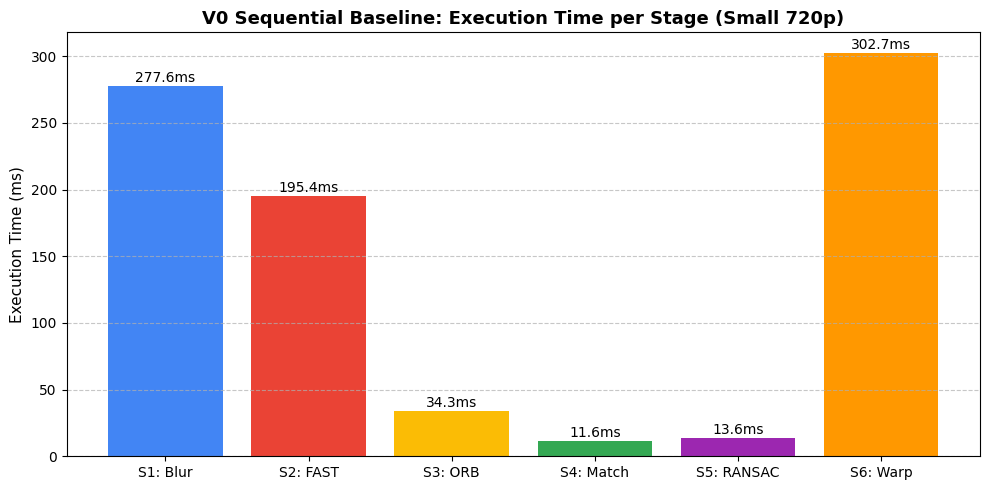

Amdahl Parallel Fraction (p): 100.00%
Theoretical Max Speedup (S_max): Idealized unbounded / below measurement resolution
Practical note: Real GPU speedup will be bounded by PCIe data transfers (H2D/D2H) and kernel launch latencies.


In [57]:
# 6.3 Execution Profile Visualization & Amdahl's Law Speedup Analysis
import os
import json
import matplotlib.pyplot as plt

p_small = "output/synthetic/metrics_small.json"
if os.path.isfile(p_small):
    with open(p_small, "r") as f:
        d = json.load(f)

    stage_labels = ["S1: Blur", "S2: FAST", "S3: ORB", "S4: Match", "S5: RANSAC", "S6: Warp"]
    stage_keys = ["stage1_preprocess", "stage2_fast_nms_topk", "stage3_orb_descriptor",
                  "stage4_matching", "stage5_ransac", "stage6_warping_blending"]
    times = [d["timing_ms"][k]["avg"] for k in stage_keys]

    plt.figure(figsize=(10, 5))
    bars = plt.bar(stage_labels, times, color=['#4285F4', '#EA4335', '#FBBC05', '#34A853', '#9C27B0', '#FF9800'])
    plt.title("V0 Sequential Baseline: Execution Time per Stage (Small 720p)", fontsize=13, fontweight='bold')
    plt.ylabel("Execution Time (ms)", fontsize=11)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    for bar in bars:
        h = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., h + 0.5, f"{h:.1f}ms", ha='center', va='bottom', fontsize=10)

    plt.tight_layout()
    plt.savefig("output/bottleneck_breakdown.png", dpi=150)
    plt.show()

    # Amdahl's Law Analysis
    t_parallel = sum(times)
    t_e2e = d["timing_ms"]["end_to_end"]["avg"]
    p = min(1.0, t_parallel / (t_e2e if t_e2e > 0 else 1.0))
    print("=" * 60)
    print(f"Amdahl Parallel Fraction (p): {p * 100:.2f}%")
    if p >= 0.999:
        print("Theoretical Max Speedup (S_max): Idealized unbounded / below measurement resolution")
        print("Practical note: Real GPU speedup will be bounded by PCIe data transfers (H2D/D2H) and kernel launch latencies.")
    else:
        s_max = 1.0 / (1.0 - p)
        print(f"Theoretical Max Speedup (S_max): {s_max:.2f}x")
    print("=" * 60)

---
## 7. VISUAL GALLERY OF STITCHED PANORAMAS

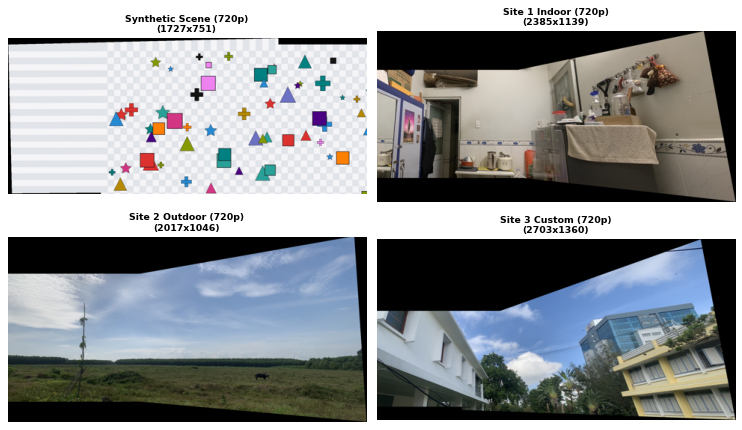

In [58]:
# 7.1 Display stitched panorama outputs
import os
import matplotlib.pyplot as plt
from PIL import Image

panoramas = [
    ("Synthetic Scene (720p)", "output/synthetic/pano_small.jpg"),
    ("Site 1 Indoor (720p)", "output/site1/pano_small.jpg"),
    ("Site 2 Outdoor (720p)", "output/site2/pano_small.jpg"),
    ("Site 3 Custom (720p)", "output/site3/pano_small.jpg")
]

plt.figure(figsize=(10, 6), dpi=75)
idx = 1
for title, p in panoramas:
    if os.path.isfile(p):
        img = Image.open(p)
        preview = img.copy()
        preview.thumbnail((480, 270))
        plt.subplot(2, 2, idx)
        plt.imshow(preview)
        plt.title(f"{title}\n({img.width}x{img.height})", fontsize=9, fontweight='bold')
        plt.axis('off')
        idx += 1

plt.tight_layout()
plt.show()

---
## 8. GPU IMPLEMENTATION PLAN (PHASES C, D, E)

### 8.1 V1 Basic CUDA Architecture (Phase C)
- Migrate all 6 stages completely to GPU device memory.
- Eliminate round-trip Host-Device transfers for intermediate feature arrays:
  - **Stage 1 (Grayscale + Gaussian Blur):** 2D Grid of Blocks $(16 \times 16)$. 1 thread per pixel. Global memory reads with boundary clamping.
  - **Stage 2 (FAST-9 + NMS + Top-K):** 2D FAST-9 detection kernel; Bounded atomic candidate list compaction; `thrust::sort_by_key` (GPU Radix Sort) for deterministic Top-K selection on 4K images.
  - **Stage 3 (ORB Descriptors):** 1 thread per keypoint. 256 test comparisons evaluated in parallel into `Descriptor` struct (8 words $\times$ 32-bit).
  - **Stage 4 (Hamming Matching):** 1D/2D grid using hardware `__popc` instruction and Lowe's ratio test.
  - **Stage 5 (RANSAC Homography):** Massively parallel hypothesis generation (2000 models); Warp-shuffle reduction for fast inlier counting.
  - **Stage 6 (Inverse Warping):** 2D Grid over panorama bounding box; Bilinear interpolation; Symmetric feathering weights.

### 8.2 APOD Methodology for V2 & V3 Optimizations
Following **Project Plan v4 Section 1.2**: No optimizations will be chosen by guesswork. After profiling V1 with `nsight-compute`, the primary bottleneck will be identified and addressed with **exactly one principal optimization** for V2 (e.g., Shared Memory Tiling for Stage 1), followed by an iterative profiling cycle for V3.

In [59]:
# 8.2 Package and verify midterm submission archive
!python scripts/package_midterm.py --group Group19

=== PACKAGING MIDTERM SUBMISSION: Group19_Midterm.zip ===
  + Added: Group19_Midterm.ipynb
  + Added: Makefile
  + Added: README.md
  + Added: requirements.txt
  + Added: project_plan_v4.md
  + Added: src/common.h
  + Added: src/cuda_utils.cuh
  + Added: src/versions.h
  + Added: src/main.cu
  + Added: src/stb_image.h
  + Added: src/stb_image_write.h
  + Added: src/stb_impl.h
  + Added: src/stb_impl.cpp
  + Added: src/v0_sequential.h
  + Added: src/v0_sequential.cpp
  + Added: scripts/preprocess_dataset.py
  + Added: scripts/generate_synthetic_test.py
  + Added: scripts/validate_metrics.py
  + Added: scripts/build_midterm_notebook.py
  + Added: scripts/package_midterm.py
  + Added: tests/test_cpu.cpp
  + Added: tests/test_scripts.py
  + Added: dataset/manifest.json
  + Added: dataset/synthetic/ground_truth.json

=== PACKAGE VERIFICATION SUCCESSFUL ===
Archive:   Group19_Midterm.zip (160.8 KB)
Entries:   24 items
SHA-256:   baa493454f668d2dc8e2b4e1394e54fe7382ce0e8ebf771e7f81bdf62dd250c